### Conceptual
1. Discuss the diﬀerences between LDA and QDA in terms of their main assumptions
about classes, decision boundaries, number of samples, and overfitting.

    Answer: LDA assumes all classes share the same covariance matrix and yield linear decision boundaris, while QDA allows a diferent covariance per class and yield quadratic boundaries. LDA need less samples and is less prone to overfitting while QDA is flexible but can overfit with small data

2. Regarding KNN:
    
    (a) How does the choice of distance metric aﬀect the performance of k-NN classification?

    Answer: The metric defines which points count as nearest so it directly shapes the decision boundary and classification accuracy. Euclidean works when features are on similar scales. Manhattan is more robust to outliers while cosine suits high dimensional or directional data

    (b) Please also discuss the concept of the curse of dimensionality and its implications for k-NN algorithm.

    Answer: In high dimensions data become sparse and distances between points tend to look similar, so nearest neighbors are less meaningful and K-NN needs much more data to work well. Mitigations include feature selection, dimensionality reduction or using other methods when the dimension is very high


### Practical

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.discrete.discrete_model import Logit
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

In [2]:
Smarket = pd.read_csv("../ISLR/data/Smarket.csv", index_col=0)
Smarket.head()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
1,2001,0.381,-0.192,-2.624,-1.055,5.010,1.1913,0.959,Up
2,2001,0.959,0.381,-0.192,-2.624,-1.055,1.2965,1.032,Up
3,2001,1.032,0.959,0.381,-0.192,-2.624,1.4112,-0.623,Down
4,2001,-0.623,1.032,0.959,0.381,-0.192,1.2760,0.614,Up
5,2001,0.614,-0.623,1.032,0.959,0.381,1.2057,0.213,Up


In [3]:
print("Number of columns:", Smarket.shape[1])
print("Column names:", list(Smarket.columns))

Number of columns: 9
Column names: ['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today', 'Direction']


In [4]:
Smarket.describe(include="all")

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
count,1250.000000,1250.000000,1250.000000,1250.000000,1250.000000,1250.00000,1250.000000,1250.000000,1250
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Up
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,648
mean,2003.016000,0.003834,0.003919,0.001716,0.001636,0.00561,1.478305,0.003138,NaN
std,1.409018,1.136299,1.136280,1.138703,1.138774,1.14755,0.360357,1.136334,NaN
min,2001.000000,-4.922000,-4.922000,-4.922000,-4.922000,-4.92200,0.356070,-4.922000,NaN
25%,2002.000000,-0.639500,-0.639500,-0.640000,-0.640000,-0.64000,1.257400,-0.639500,NaN
50%,2003.000000,0.039000,0.039000,0.038500,0.038500,0.03850,1.422950,0.038500,NaN
75%,2004.000000,0.596750,0.596750,0.596750,0.596750,0.59700,1.641675,0.596750,NaN


In [5]:
print("Number of data points:", Smarket.shape[0])

Number of data points: 1250


In [6]:
Smarket

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
1,2001,0.381,-0.192,-2.624,-1.055,5.010,1.19130,0.959,Up
2,2001,0.959,0.381,-0.192,-2.624,-1.055,1.29650,1.032,Up
3,2001,1.032,0.959,0.381,-0.192,-2.624,1.41120,-0.623,Down
4,2001,-0.623,1.032,0.959,0.381,-0.192,1.27600,0.614,Up
5,2001,0.614,-0.623,1.032,0.959,0.381,1.20570,0.213,Up
...,...,...,...,...,...,...,...,...,...
1246,2005,0.422,0.252,-0.024,-0.584,-0.285,1.88850,0.043,Up
1247,2005,0.043,0.422,0.252,-0.024,-0.584,1.28581,-0.955,Down
1248,2005,-0.955,0.043,0.422,0.252,-0.024,1.54047,0.130,Up
1249,2005,0.130,-0.955,0.043,0.422,0.252,1.42236,-0.298,Down


In [7]:
X_corr = Smarket.drop(columns=["Direction"])
corr_matrix = X_corr.corr(method="pearson")
print("Correlation matrix:")
display(corr_matrix)

Correlation matrix:


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,0.029700,0.030596,0.033195,0.035689,0.029788,0.539006,0.030095
Lag1,0.029700,1.000000,-0.026294,-0.010803,-0.002986,-0.005675,0.040910,-0.026155
Lag2,0.030596,-0.026294,1.000000,-0.025897,-0.010854,-0.003558,-0.043383,-0.010250
Lag3,0.033195,-0.010803,-0.025897,1.000000,-0.024051,-0.018808,-0.041824,-0.002448
Lag4,0.035689,-0.002986,-0.010854,-0.024051,1.000000,-0.027084,-0.048414,-0.006900
Lag5,0.029788,-0.005675,-0.003558,-0.018808,-0.027084,1.000000,-0.022002,-0.034860
Volume,0.539006,0.040910,-0.043383,-0.041824,-0.048414,-0.022002,1.000000,0.014592
Today,0.030095,-0.026155,-0.010250,-0.002448,-0.006900,-0.034860,0.014592,1.000000


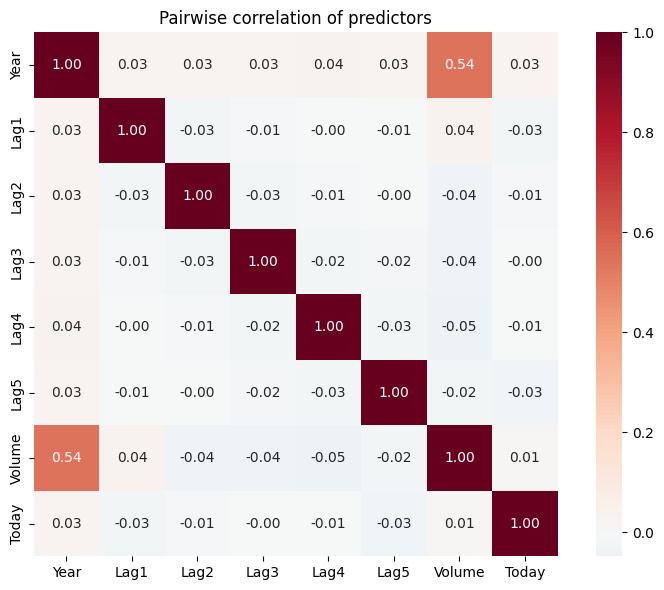

In [8]:
plt.figure(figsize=(8, 6))
plt.title("Pairwise correlation of predictors")

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)

plt.tight_layout()
plt.show()

Interpretation: 

The only notable corelation is between Year and Volume (0.54). Lag1–lag5 and Today show very weak correlations with each other. Multicollinearity is not a major concern except for Year and Volume

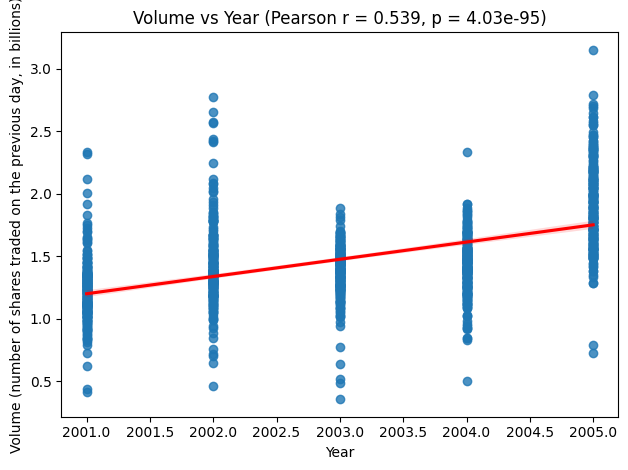

In [9]:
sns.regplot(data=Smarket, x="Year", y="Volume", ci=95, line_kws={"color": "red"})
r, p = stats.pearsonr(Smarket["Year"], Smarket["Volume"])

plt.xlabel("Year")
plt.ylabel("Volume (number of shares traded on the previous day, in billions)")
plt.title(f"Volume vs Year (Pearson r = {r:.3f}, p = {p:.2e})")

plt.tight_layout()
plt.show()

Interpretation:

 Volume tends to increase over time (positive correlation with Year) trading activity grow from 2001 to 2005

In [10]:
y = (Smarket["Direction"] == "Up").astype(int)  # 1 = Up, 0 = Down
X_full = sm.add_constant(Smarket[["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]])
glm_fit = Logit(y, X_full).fit()
print(glm_fit.summary())

Optimization terminated successfully.
         Current function value: 0.691034
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:              Direction   No. Observations:                 1250
Model:                          Logit   Df Residuals:                     1243
Method:                           MLE   Df Model:                            6
Date:                Sun, 15 Feb 2026   Pseudo R-squ.:                0.002074
Time:                        15:32:06   Log-Likelihood:                -863.79
converged:                       True   LL-Null:                       -865.59
Covariance Type:            nonrobust   LLR p-value:                    0.7319
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.1260      0.241     -0.523      0.601      -0.598       0.346
Lag1          -0.0731      0.

In [11]:
glm_fit.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-0.126000,0.240737,-0.523394,0.600700,-0.597836,0.345836
Lag1,-0.073074,0.050168,-1.456583,0.145232,-0.171401,0.025254
Lag2,-0.042301,0.050086,-0.844568,0.398352,-0.140469,0.055866
Lag3,0.011085,0.049939,0.221974,0.824334,-0.086793,0.108963
Lag4,0.009359,0.049974,0.187275,0.851445,-0.088589,0.107307
Lag5,0.010313,0.049512,0.208296,0.834998,-0.086728,0.107354
Volume,0.135441,0.158361,0.855266,0.392404,-0.174941,0.445822


Interpretation:

 None of the predictors are statistically significant at 0.05 (p values > 0.05). Lag1 has the smallest p-value equal 0.15

In [12]:
glm_probs = glm_fit.predict(X_full)

print(f"First 10 predicted probabilities: {glm_probs.head(10).values}")

First 10 predicted probabilities: [0.50708413 0.48146788 0.48113883 0.51522236 0.51078116 0.50695646
 0.49265087 0.50922916 0.51761353 0.48883778]


In [13]:
contrasts_direction = pd.DataFrame({"Up": [0, 1]}, index=["Down", "Up"])

print("Contrasts:")
print(contrasts_direction)

Contrasts:
      Up
Down   0
Up     1


In [14]:
glm_pred = np.where(glm_probs > 0.5, "Up", "Down")
glm_pred = pd.Series(glm_pred, index=Smarket.index)

In [15]:
print("Confusion matrix (rows = predicted, columns = actual):")

cm = confusion_matrix(Smarket["Direction"], glm_pred, labels=["Down", "Up"])

print(pd.DataFrame(cm, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy:", accuracy_score(Smarket["Direction"], glm_pred))

Confusion matrix (rows = predicted, columns = actual):
      Down   Up
Down   145  457
Up     141  507
Accuracy: 0.5216


Interpretation: 

Accuracy is closeto 52%.  Model predicts Up more often but also many Down days are misclassified as Up. Only slightly better than random predictoin, consistent with no significant predictors

In [16]:
X_12 = sm.add_constant(Smarket[["Lag1", "Lag2"]])

glm_fit_12 = Logit(y, X_12).fit()
glm_probs_12 = glm_fit_12.predict(X_12)
glm_pred_12 = np.where(glm_probs_12 > 0.5, "Up", "Down")
glm_pred_12 = pd.Series(glm_pred_12, index=Smarket.index)

print("Confusion matrix (Lag1 and Lag2 only):")

cm_12 = confusion_matrix(Smarket["Direction"], glm_pred_12, labels=["Down", "Up"])

print(pd.DataFrame(cm_12, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy:", accuracy_score(Smarket["Direction"], glm_pred_12))

Optimization terminated successfully.
         Current function value: 0.691361
         Iterations 4
Confusion matrix (Lag1 and Lag2 only):
      Down   Up
Down   114  488
Up     102  546
Accuracy: 0.528


Interpretation: 
With only Lag1 and Lag2, accuracy is about 52.8%, bit higher than the full model. The simpler model avoids noise from non-significant predictors

In [17]:
X_lda = Smarket[["Lag1", "Lag2"]]
y_lda = Smarket["Direction"]
lda_fit = LinearDiscriminantAnalysis()
lda_fit.fit(X_lda, y_lda)

print("Prior probabilities of groups:")
for cls, pr in zip(lda_fit.classes_, lda_fit.priors_):
    print(f"  {cls}: {pr:.4f}")
print("Group means:")
print(pd.DataFrame(lda_fit.means_, index=lda_fit.classes_, columns=["Lag1", "Lag2"]))
print("Coefficients of linear discriminants (scaling):")
print(pd.DataFrame(lda_fit.scalings_, index=["Lag1", "Lag2"], columns=["LD1"]))

Prior probabilities of groups:
  Down: 0.4816
  Up: 0.5184
Group means:
          Lag1      Lag2
Down  0.050686  0.032297
Up   -0.039691 -0.022444
Coefficients of linear discriminants (scaling):
           LD1
Lag1 -0.756761
Lag2 -0.470787


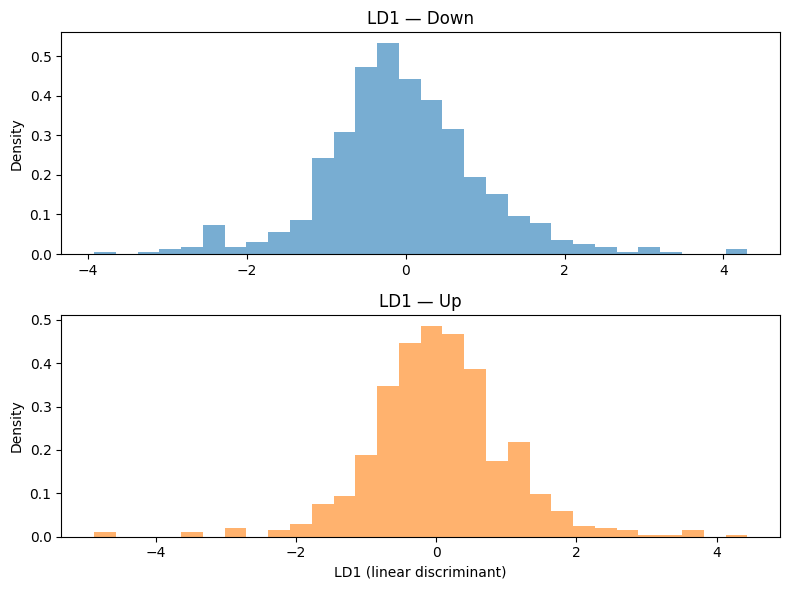

In [18]:
ld1_scores = lda_fit.transform(X_lda).ravel()
ld1_df = pd.DataFrame({"LD1": ld1_scores, "Direction": y_lda.values})

fig, axes = plt.subplots(2, 1, figsize=(8, 6))

for ax, direction in zip(axes, ["Down", "Up"]):
    subset = ld1_df[ld1_df["Direction"] == direction]["LD1"]
    ax.hist(subset, bins=30, alpha=0.6, color="C0" if direction == "Down" else "C1", density=True)
    ax.set_ylabel("Density")
    ax.set_title(f"LD1 — {direction}")

axes[1].set_xlabel("LD1 (linear discriminant)")

plt.tight_layout()
plt.show()

Interpretation: 

Priors are close to 0.5. Group meansthat on Down days lag1/lag2 are slightly positive on average and  on Up days slightly negative. The linear discriminant uses negative weights for lag1 and lag2

In [19]:
lda_pred = lda_fit.predict(X_lda)

print("Confusion matrix (LDA):")

cm_lda = confusion_matrix(Smarket["Direction"], lda_pred, labels=["Down", "Up"])

print(pd.DataFrame(cm_lda, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy:", accuracy_score(Smarket["Direction"], lda_pred))

Confusion matrix (LDA):
      Down   Up
Down   114  488
Up     102  546
Accuracy: 0.528


Interpretation: 

LDA with Lag1 and Lag2 gives the same confusion matrix and accuracy (52.8%) as the logistic model with Lag1+Lag2

In [20]:
qda_fit = QuadraticDiscriminantAnalysis()
qda_fit.fit(X_lda, y_lda)

print("Prior probabilities of groups:")

for cls, pr in zip(qda_fit.classes_, qda_fit.priors_):
    print(f"  {cls}: {pr:.4f}")

print("Group means:")
print(pd.DataFrame(qda_fit.means_, index=qda_fit.classes_, columns=["Lag1", "Lag2"]))

Prior probabilities of groups:
  Down: 0.4816
  Up: 0.5184
Group means:
          Lag1      Lag2
Down  0.050686  0.032297
Up   -0.039691 -0.022444


Interpretation: 

QDA use same priors and group means as LDA but allows different covariance matrices per class 

In [21]:
qda_pred = qda_fit.predict(X_lda)

print("Confusion matrix (QDA):")

cm_qda = confusion_matrix(Smarket["Direction"], qda_pred, labels=["Down", "Up"])

print(pd.DataFrame(cm_qda, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy:", accuracy_score(Smarket["Direction"], qda_pred))

Confusion matrix (QDA):
      Down   Up
Down   109  493
Up      94  554
Accuracy: 0.5304


Interpretation:

 QDA achieves about 53% accuracy, bit higher than LDA and logistic regression. 
QDA uses a separate covariance matrix per class (quadratic decision boundary), so it can capture nonlinear separation between Down and Up days that LDA and logistic regression which use linear boundaries cant

In [22]:
train = Smarket["Year"] < 2005
Smarket_2005 = Smarket.loc[~train]
X_train = Smarket.loc[train, ["Lag1", "Lag2"]]
X_test = Smarket.loc[~train, ["Lag1", "Lag2"]]
train_Direction = Smarket.loc[train, "Direction"]
Direction_2005 = Smarket.loc[~train, "Direction"]

print("Train size:", X_train.shape[0])
print("Smarket_2005 shape:", Smarket_2005.shape)

Train size: 998
Smarket_2005 shape: (252, 9)


In [23]:
np.random.seed(1)

knn_pred_1 = KNeighborsClassifier(n_neighbors=1).fit(X_train, train_Direction).predict(X_test)

print("Confusion matrix (KNN k=1):")

cm_k1 = confusion_matrix(Direction_2005, knn_pred_1, labels=["Down", "Up"])

print(pd.DataFrame(cm_k1, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy on 2005:", accuracy_score(Direction_2005, knn_pred_1))

Confusion matrix (KNN k=1):
      Down  Up
Down    43  68
Up      58  83
Accuracy on 2005: 0.5


In [24]:
knn_pred_3 = KNeighborsClassifier(n_neighbors=3).fit(X_train, train_Direction).predict(X_test)

print("Confusion matrix (KNN k=3):")

cm_k3 = confusion_matrix(Direction_2005, knn_pred_3, labels=["Down", "Up"])

print(pd.DataFrame(cm_k3, index=["Down", "Up"], columns=["Down", "Up"]))
print("Accuracy on 2005:", accuracy_score(Direction_2005, knn_pred_3))

Confusion matrix (KNN k=3):
      Down  Up
Down    48  63
Up      55  86
Accuracy on 2005: 0.5317460317460317


Interpretation:

With k=1, accuracy on the 2005 test set is 50% (random). 1-NN is very sensitive to noise and does not generalize well


With k=3, accuracy improves to about 53.6%. Using a few neighbors smooths the boundary and can improve generalization compared to k=1

Champion: K-Nearest Neighbors with k=3, with about 53.2% accuracy on the 2005 test set.

Why this was maybe expected:

1. Logistic regression, LDA, and QDA were assessed on the full dataset (in-sample), so their accuracies are not directly comparable to out-of-sample performance. KNN with k=3 is the best result we have on the 2005 test set

2. QDA (53.04% in-sample) and KNN k=3 (53.2% on 2005) both beat the linear methods (logistic and LDA at ~52.8%). That suggests the boundary between Up and Down may be somewhat curved rather than strictly linear, which fits QDA’s quadratic boundary and KNN’s flexible, local boundary.

3. With k=1, test accuracy was 50% (random), due to overfitting to noise. Using k=3 smooths the decision boundary and often improves generalization without losing too much flexibility, which is consistent with the gain from 50% to ~53.2%.

4. Only Lag1 and Lag2 are used, so we are in 2D. Distances remain meaningful and nearest neighbors are informative, which makes KNN a plausible candidate.

5. All accuracies are only slightly above 50%, which matches the idea that lagged returns have limited predictive power for next-day direction. The “champion” is only a small improvement over random, so the result is both the best among the methods tried and consistent with the difficulty of the task.